In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

import pickle
import time
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [3]:
df = pd.read_csv('weather_data.csv')
df.drop(columns = ['Unnamed: 0', 'incident_latitude', 'incident_longitude', 'incident_date_created'], inplace = True)
df.head()

,fire_started?,Elevation,temperature_2m_max,temperature_2m_min,daylight_duration,sunshine_duration,uv_index_max,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,et0_fao_evapotranspiration,cloud_cover_mean,relative_humidity_2m_max,relative_humidity_2m_min,surface_pressure_max,surface_pressure_min
0,True,142.0,87.857600,49.247600,49805.977,44803.945,7.70,0.0,0.0,8.815597,20.8041,0.244245,42.041668,72.0,16.0,999.06384,995.19250
1,True,634.0,81.365005,60.305000,48694.004,34689.043,8.70,0.0,0.0,25.787672,47.4244,0.356950,31.000000,37.0,9.0,937.44836,931.04100
2,False,1810.0,65.043500,33.723500,49877.473,42414.965,8.50,0.0,0.0,23.492760,31.5417,0.233666,4.708334,48.0,9.0,821.74290,813.92250
3,True,1075.0,82.297390,52.777397,49010.100,45562.844,8.60,0.0,0.0,14.085998,15.2116,0.277917,1.458333,47.0,11.0,897.75420,889.85390
4,True,452.0,93.328700,55.708702,49183.010,45576.700,8.25,0.0,0.0,21.269154,27.5151,0.318660,10.416667,62.0,9.0,962.82263,958.66864


In [4]:
output = df['fire_started?']
input = df.drop(columns = 'fire_started?')
input.head()

,Elevation,temperature_2m_max,temperature_2m_min,daylight_duration,sunshine_duration,uv_index_max,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,et0_fao_evapotranspiration,cloud_cover_mean,relative_humidity_2m_max,relative_humidity_2m_min,surface_pressure_max,surface_pressure_min
0,142.0,87.857600,49.247600,49805.977,44803.945,7.70,0.0,0.0,8.815597,20.8041,0.244245,42.041668,72.0,16.0,999.06384,995.19250
1,634.0,81.365005,60.305000,48694.004,34689.043,8.70,0.0,0.0,25.787672,47.4244,0.356950,31.000000,37.0,9.0,937.44836,931.04100
2,1810.0,65.043500,33.723500,49877.473,42414.965,8.50,0.0,0.0,23.492760,31.5417,0.233666,4.708334,48.0,9.0,821.74290,813.92250
3,1075.0,82.297390,52.777397,49010.100,45562.844,8.60,0.0,0.0,14.085998,15.2116,0.277917,1.458333,47.0,11.0,897.75420,889.85390
4,452.0,93.328700,55.708702,49183.010,45576.700,8.25,0.0,0.0,21.269154,27.5151,0.318660,10.416667,62.0,9.0,962.82263,958.66864


In [5]:
train_X, test_X, train_y, test_y = train_test_split(input, output, test_size = 0.2, random_state = 1)

In [6]:
rf_ml = RandomForestClassifier(random_state = 1)

In [7]:
start = time.time()
rf_ml.fit(train_X, train_y)
stop = time.time()
print(f"Time Taken: {stop - start} seconds")

Time Taken: 0.3277449607849121 seconds


In [8]:
y_pred = rf_ml.predict(test_X)

In [9]:
y_pred_train = rf_ml.predict(train_X)

In [10]:
class_report = classification_report(test_y, y_pred, output_dict=True)
cr_df = pd.DataFrame(class_report)
cr_df.to_csv('rf_report.csv')
cr_df

,False,True,accuracy,macro avg,weighted avg
precision,0.916944,0.743590,0.881266,0.830267,0.878980
recall,0.932432,0.698795,0.881266,0.815614,0.881266
f1-score,0.924623,0.720497,0.881266,0.822560,0.879920
support,296.000000,83.000000,0.881266,379.000000,379.000000


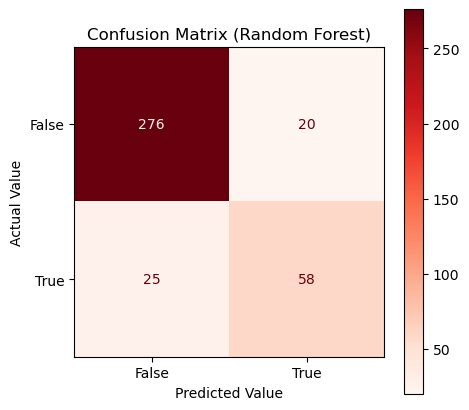

In [15]:
cm = confusion_matrix(test_y, y_pred, labels = rf_ml.classes_)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=rf_ml.classes_)

fig, ax = plt.subplots(figsize=(5,5))
display.plot(cmap = "Reds", ax = ax)
plt.xlabel('Predicted Value')
plt.ylabel('Actual Value')
plt.title('Confusion Matrix (Random Forest)')
plt.savefig('rf_matrix.svg')
fig

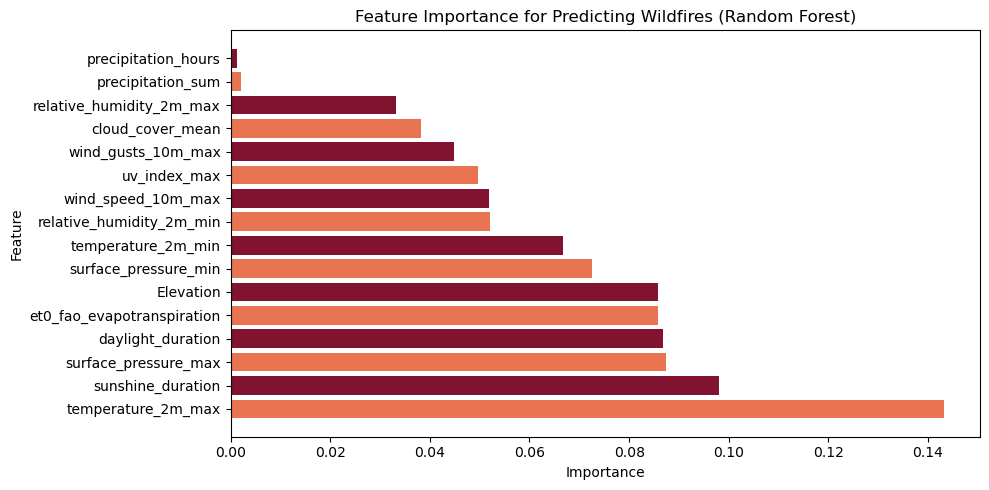

In [16]:
importance = rf_ml.feature_importances_

feat_imp = pd.DataFrame(list(zip(train_X.columns, importance)),
                        columns = ['Feature', 'Importance'])

feat_imp = feat_imp.sort_values(by = 'Importance', ascending=False).reset_index(drop=True)

feat_imp_chart = plt.figure(figsize=(10, 5))
plt.barh(feat_imp['Feature'], feat_imp['Importance'], color = ['#E97451', '#811331'])

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance for Predicting Wildfires (Random Forest)')
plt.tight_layout()
plt.savefig('rf_importance.svg')
feat_imp_chart

In [13]:
probability = rf_ml.predict_proba(test_X)
fire_probability = []
for i in probability:
    fire_probability.append(i[1])

fire_probability

[np.float64(0.0),
 np.float64(0.79),
 np.float64(0.43),
 np.float64(0.85),
 np.float64(0.02),
 np.float64(0.01),
 np.float64(0.34),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.23),
 np.float64(0.02),
 np.float64(0.41),
 np.float64(0.34),
 np.float64(0.02),
 np.float64(0.14),
 np.float64(0.0),
 np.float64(0.02),
 np.float64(0.02),
 np.float64(0.09),
 np.float64(0.52),
 np.float64(0.26),
 np.float64(0.88),
 np.float64(0.04),
 np.float64(0.0),
 np.float64(0.17),
 np.float64(0.39),
 np.float64(0.02),
 np.float64(0.01),
 np.float64(0.79),
 np.float64(0.18),
 np.float64(0.05),
 np.float64(0.01),
 np.float64(0.0),
 np.float64(0.2),
 np.float64(0.07),
 np.float64(0.03),
 np.float64(0.0),
 np.float64(0.01),
 np.float64(0.02),
 np.float64(0.01),
 np.float64(0.0),
 np.float64(0.33),
 np.float64(0.01),
 np.float64(0.19),
 np.float64(0.1),
 np.float64(0.68),
 np.float64(0.18),
 np.float64(0.02),
 np.float64(0.03),
 np.float64(0.26),
 np.float64(0.74),
 np.float64(0.17),
 np.float64(0.85),
 np

In [14]:
rf_pickle = open('rf_ml.pickle', 'wb')
pickle.dump(rf_ml, rf_pickle)
rf_pickle.close()